In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import glob

# Style settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Paths
INPUT_DIR = Path(r"d:\Projects\OncoGraphRAG\data\extracted relations")

In [2]:
def load_extracted_relations(directory):
    all_data = []
    files = list(directory.glob("*.jsonl"))
    
    print(f"Found {len(files)} files in {directory}")
    
    for file_path in files:
        print(f"Loading {file_path.name}...")
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                try:
                    data = json.loads(line.strip())
                    all_data.append(data)
                except json.JSONDecodeError:
                    continue
                    
    return pd.DataFrame(all_data)

# Load the dataframe
df = load_extracted_relations(INPUT_DIR)

# Display basics
print(f"\nTotal Relations Extracted: {len(df)}")
print("Columns:", df.columns.tolist())
df.head()

Found 8 files in d:\Projects\OncoGraphRAG\data\extracted relations
Loading Breast_Cancer_relations_500.jsonl...
Loading Cervical_Cancer_relations_500.jsonl...
Loading Colorectal_Cancer_relations_500.jsonl...
Loading Leukemia_relations_500.jsonl...
Loading Lung_Cancer_relations_500.jsonl...
Loading Melanoma_relations_500.jsonl...
Loading Oral_Cancer_relations_500.jsonl...
Loading Prostate_Cancer_relations_500.jsonl...

Total Relations Extracted: 17504
Columns: ['relation_type', 'entity1_type', 'entity1_name', 'entity2_type', 'entity2_name', 'efficacy', 'trial_phase', 'reliability_score', 'pub_id']


,relation_type,entity1_type,entity1_name,entity2_type,entity2_name,efficacy,trial_phase,reliability_score,pub_id
0,treat,treatment,regional nodal irradiation,disease,breast cancer,Negative: did not significantly increase invas...,Phase III,70,PMID:40466065
1,treat,treatment,T-DM1,disease,HER2-positive early breast cancer,Positive: hazard ratio 0.50; P<0.001,Phase III,95,PMID:30516102
2,treat,treatment,trastuzumab,disease,HER2-positive early breast cancer,Not Stated,Phase III,70,PMID:30516102
3,present,disease,residual invasive disease,disease,HER2-positive early breast cancer,Not Stated,Phase III,70,PMID:30516102
4,affect,treatment,T-DM1,complication,adverse events,Not Stated,Phase III,70,PMID:30516102


C:\Users\laksh\AppData\Local\Temp\ipykernel_19700\4046496068.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='relation_type', order=df['relation_type'].value_counts().index, palette='viridis')


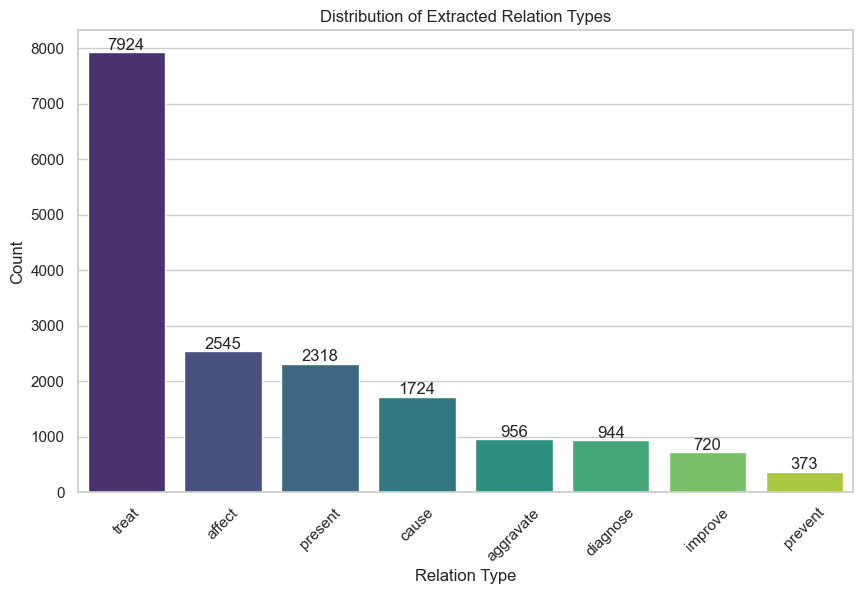

In [3]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='relation_type', order=df['relation_type'].value_counts().index, palette='viridis')
plt.title('Distribution of Extracted Relation Types')
plt.xlabel('Relation Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Add counts on top
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

C:\Users\laksh\AppData\Local\Temp\ipykernel_19700\599492841.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=entity_types, order=entity_types.value_counts().index, palette='viridis')


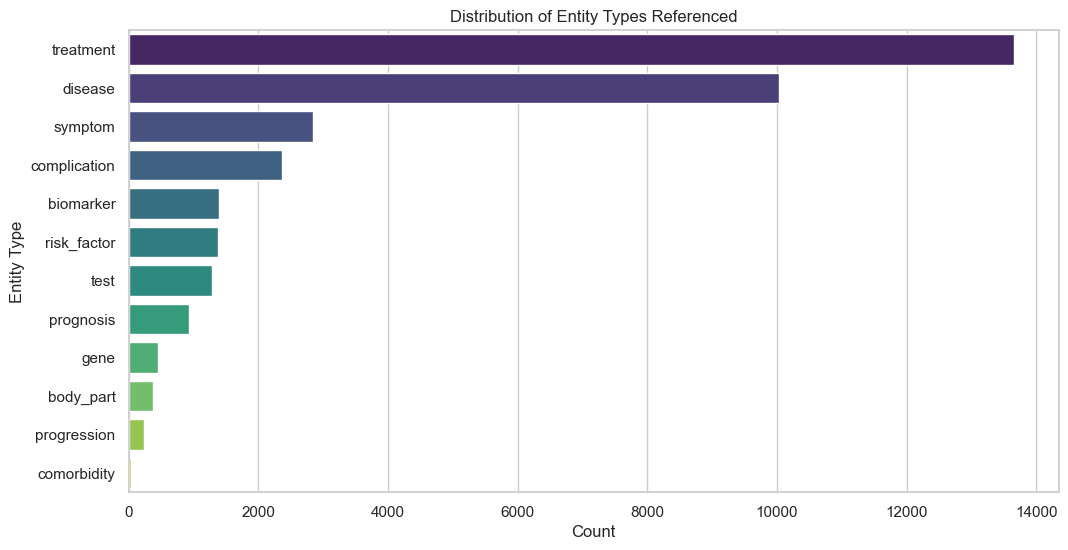

In [4]:
# Melt the dataframe to count entity types generally (Subject vs Object)
entity_types = pd.concat([
    df['entity1_type'].rename('Entity Type'),
    df['entity2_type'].rename('Entity Type')
])

plt.figure(figsize=(12, 6))
sns.countplot(y=entity_types, order=entity_types.value_counts().index, palette='viridis')
plt.title('Distribution of Entity Types Referenced')
plt.xlabel('Count')
plt.ylabel('Entity Type')
plt.show()

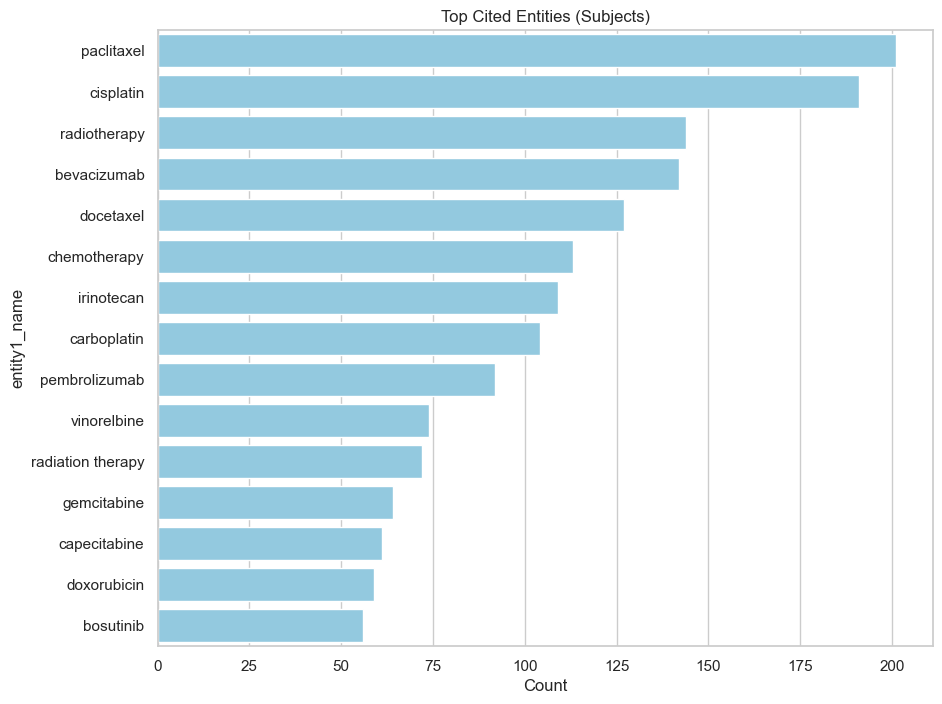

In [5]:
def plot_top_n(dataframe, column, title, n=15, color='teal'):
    top_items = dataframe[column].value_counts().head(n)
    
    plt.figure(figsize=(10, 8))
    sns.barplot(x=top_items.values, y=top_items.index, color=color)
    plt.title(title)
    plt.xlabel('Count')
    plt.show()

# Visualize top treatments mention
treatments = df[df['entity1_type'] == 'treatment']['entity1_name']
plot_top_n(df, 'entity1_name', 'Top Cited Entities (Subjects)', n=15, color='skyblue')

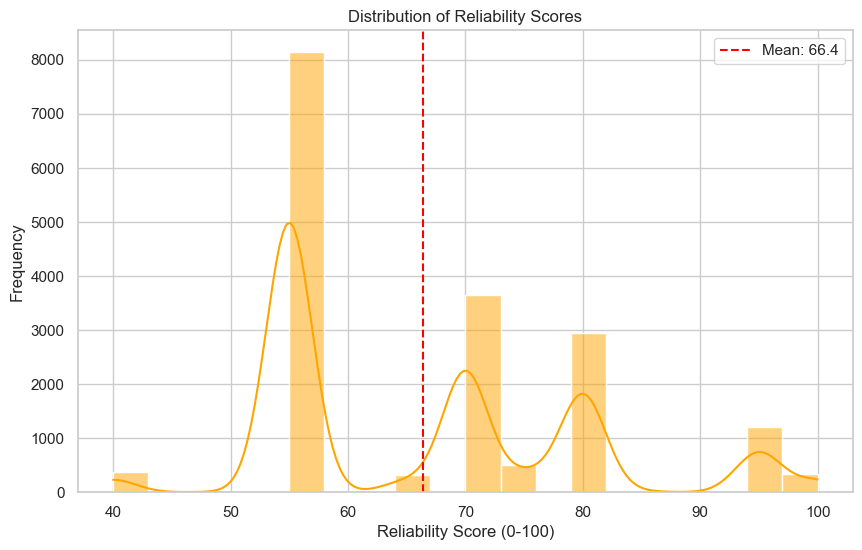

In [6]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='reliability_score', bins=20, kde=True, color='orange')
plt.title('Distribution of Reliability Scores')
plt.xlabel('Reliability Score (0-100)')
plt.ylabel('Frequency')
plt.axvline(df['reliability_score'].mean(), color='red', linestyle='--', label=f"Mean: {df['reliability_score'].mean():.1f}")
plt.legend()
plt.show()

C:\Users\laksh\AppData\Local\Temp\ipykernel_19700\3387115025.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=phase_counts.index, y=phase_counts.values, palette='viridis')


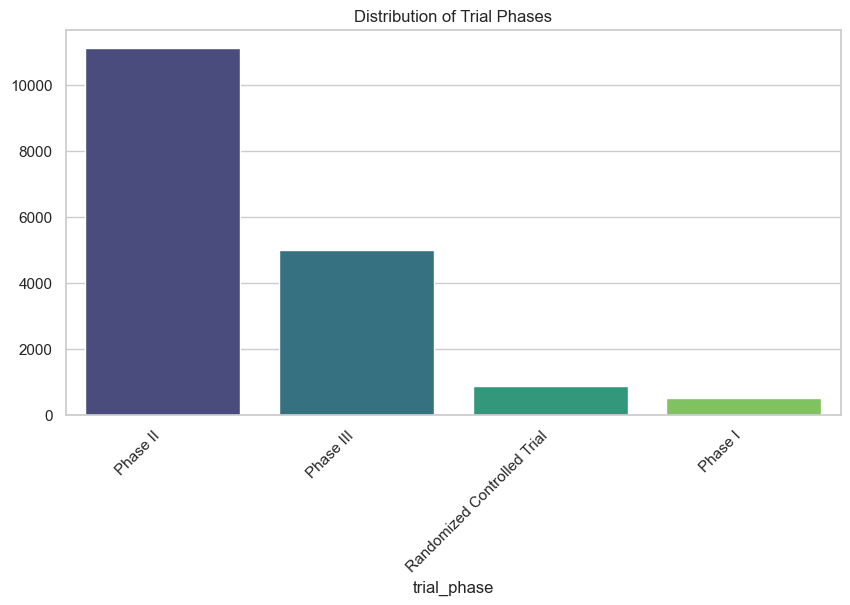

C:\Users\laksh\AppData\Local\Temp\ipykernel_19700\3387115025.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='efficacy_category', palette='viridis')


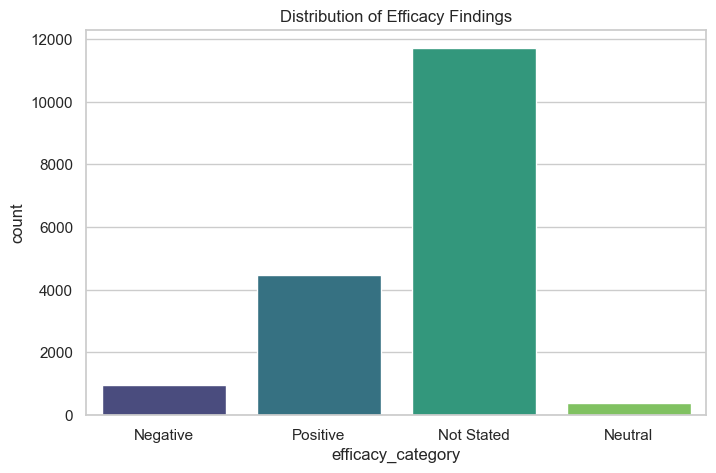

In [7]:
# 1. Trial Phase Distribution
plt.figure(figsize=(10, 5))
phase_counts = df['trial_phase'].value_counts()
sns.barplot(x=phase_counts.index, y=phase_counts.values, palette='viridis')
plt.title('Distribution of Trial Phases')
plt.xticks(rotation=45, ha='right')
plt.show()

# 2. Efficacy Categories
# We need to parse the efficacy prefix (Positive, Negative, etc.)
def get_efficacy_label(text):
    text = str(text).lower()
    if text.startswith('positive'): return 'Positive'
    if text.startswith('negative'): return 'Negative'
    if text.startswith('neutral') or text.startswith('inconclusive'): return 'Neutral'
    if text.startswith('not stated') or 'not stated' in text: return 'Not Stated'
    return 'Other'

df['efficacy_category'] = df['efficacy'].apply(get_efficacy_label)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='efficacy_category', palette='viridis')
plt.title('Distribution of Efficacy Findings')
plt.show()

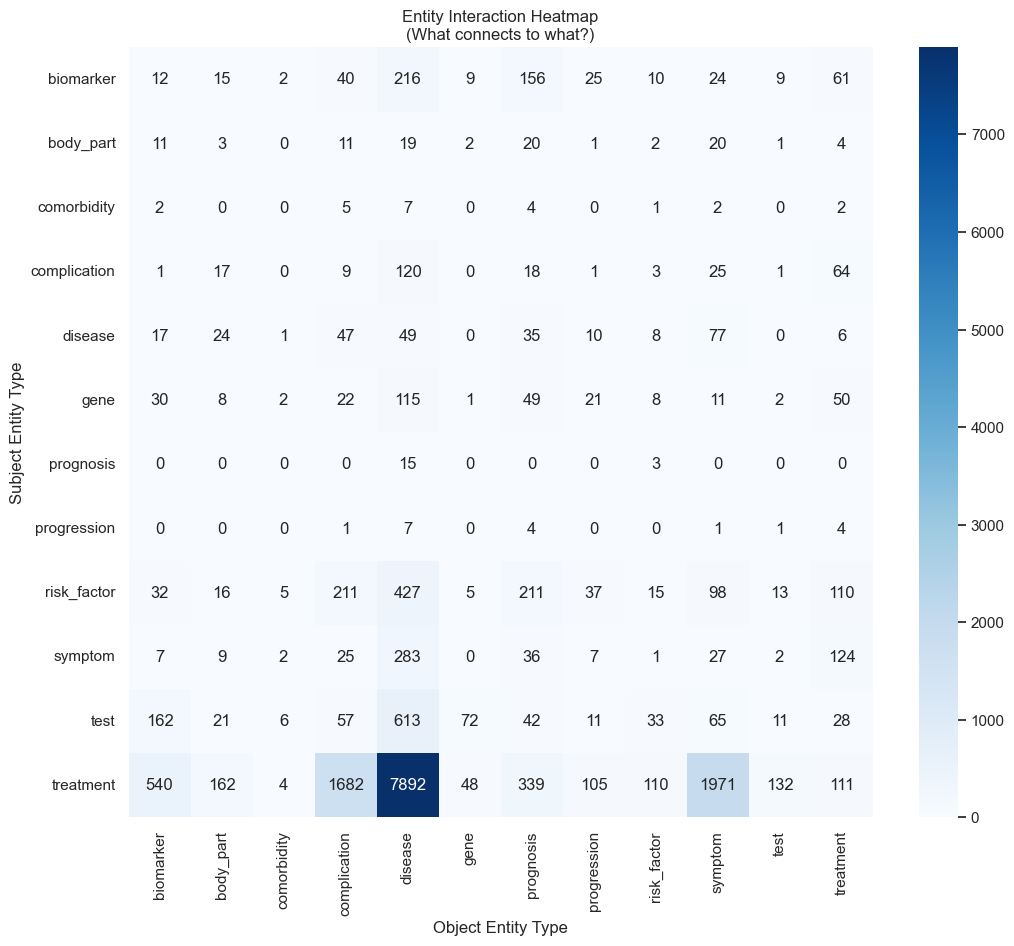

In [8]:
# Create a cross-tabulation of Entity 1 Type vs Entity 2 Type
interaction_matrix = pd.crosstab(df['entity1_type'], df['entity2_type'])

plt.figure(figsize=(12, 10))
sns.heatmap(interaction_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Entity Interaction Heatmap\n(What connects to what?)')
plt.xlabel('Object Entity Type')
plt.ylabel('Subject Entity Type')
plt.show()